# Tarea 2 · Parte 1 — Corpus y extracción (OCR + ASR)

> **Pregunta del proyecto:** ¿Pueden convertir documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

Este notebook arma dos corpus del Perú del siglo XX y los convierte en texto: **25 documentos** (prensa
electoral de 1939 y 1945, leyes y manuscritos de 1912 a 1921) leídos con **PaddleOCR**, y **92 minutos de
noticieros cinematográficos de la década de 1940** transcritos con **faster-whisper**, VAD y diarización.

## Configuración inicial

| Dato | Valor |
|---|---|
| Fecha de extracción | 25 de octubre de 2026 (descargas de Wikimedia Commons y OCR/ASR locales) |
| OCR | PaddleOCR **3.7.0**, modelo PP-OCRv6 *medium* (detector + reconocedor multilingüe con español), motor PaddlePaddle 3.3.1 en CPU |
| ASR | faster-whisper **1.2.1** con **Whisper large-v3-turbo** (CTranslate2, int8, CPU), `beam_size=5`, VAD Silero, `language="es"` |
| Diarización | huellas de voz WeSpeaker ResNet34 (pyannote.audio 4.0.7) + clustering jerárquico (coseno, umbral 0,7), con `voz.py` de la sesión 13 |
| Entorno | Python 3.12, los grupos `docai` y `audio` del curso (`uv sync --group docai`, `uv sync --group audio`); versiones exactas impresas abajo |
| Equipo | laptop con Intel Core i5-8250U (4 núcleos), 24 GB de RAM, sin GPU utilizable (GeForce de 2 GB con driver CUDA 12.0) |

### Fuentes y licencias

| Corpus | Fuente | Licencia | Registros |
|---|---|---|---|
| Documentos impresos y fotos | Capturas propias de *El Comercio* y *La Crónica* (1939 y 1945), Leyes 8901 (1939) y folleto «Tres discursos» del Bloque Antifascista Peruano (1945) | Prensa: dominio público en el Perú (D. Leg. 822, art. 53: obra de persona jurídica con más de 70 años). Ley: texto oficial no protegido (art. 9). Folleto: uso académico, **sus imágenes no se publican** | 16 |
| Manuscritos | Biblioteca Nacional del Perú y archivo Burzagli en Wikimedia Commons (cartas de 1912 y 1917, tarjeta de 1912, documentos de 1921) | CC0, Public Domain Mark, dominio público y CC BY-SA 3.0 | 9 |
| Audio | 31 noticieros peruanos de 1940-1948 y un tramo de *Alerta en la frontera* (1942), digitalizados por la BNP y publicados en Wikimedia Commons | Public Domain Mark (del propietario), CC0, dominio público y CC BY 4.0 | 32 clips · 92 min |

El detalle por archivo (URL, licencia y cómo recuperarlo) se exporta al final a `datos/fuentes.csv`.
Los archivos originales y las salidas pesadas viven en `datos/raw/`, que no se versiona.

In [1]:
import hashlib
import json
import os
import re
import sys
import time
import warnings
from pathlib import Path

os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"   # no probar la conexión a cada servidor de modelos
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
warnings.filterwarnings("ignore")

import faster_whisper
import matplotlib.pyplot as plt
import numpy as np
import paddle
import paddleocr
import pandas as pd
import plotly
import plotly.express as px
import plotly.io as pio
import pyannote.audio
import pymupdf
import torch
import transformers
from matplotlib.patches import Patch, Rectangle
from PIL import Image

import fuentes_audio
import procesar_audio as pa
import procesar_documentos as pd_ocr
import seudonimos
import voz
from fuentes_documentos import CARPETA as DOCS, FUENTES_PROPIAS

# Los gráficos de Plotly se guardan también como PNG para que se vean en GitHub
import logging
logging.getLogger().setLevel(logging.ERROR)              # sin registros INFO de httpx, kaleido o paddlex
for nombre in list(logging.root.manager.loggerDict):
    logging.getLogger(nombre).setLevel(logging.ERROR)
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()

pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width, pio.renderers["png"].height = 950, 500
pd.set_option("display.max_colwidth", 90)
%config InlineBackend.figure_formats = ["jpeg"]

DATOS = Path("datos")
AUDIO = DATOS / "raw" / "audio"
COLORES = {"impreso": "#2a78d6", "foto": "#eb6834", "manuscrito": "#7a5195"}

print(f"PaddleOCR {paddleocr.__version__} · PaddlePaddle {paddle.__version__} · PyMuPDF {pymupdf.__version__}")
print(f"faster-whisper {faster_whisper.__version__} · modelo {voz.MODELOS['faster-whisper']['hf']}")
print(f"pyannote.audio {pyannote.audio.__version__} · torch {torch.__version__} · transformers {transformers.__version__}")
print(f"pandas {pd.__version__} · plotly {plotly.__version__} · Python {sys.version.split()[0]}")

PaddleOCR 3.7.0 · PaddlePaddle 3.3.1 · PyMuPDF 2.0
faster-whisper 1.2.1 · modelo mobiuslabsgmbh/faster-whisper-large-v3-turbo
pyannote.audio 4.0.7 · torch 2.14.1+cpu · transformers 5.20.2
pandas 3.1.0 · plotly 7.1.0 · Python 3.12.15


---
# A · Documentos

## 1. El corpus: 25 documentos en tres niveles de dificultad

Cada documento es **una imagen**: una página de un PDF de capturas propias o un archivo de Commons. El
catálogo (`procesar_documentos.CATALOGO`) fija el tipo de cada uno con un criterio visual:

- **impreso**: texto tipográfico recto, buen contraste, fondo limpio;
- **foto**: imagen tomada con celular de un papel curvado o inclinado, o con sombras (el folleto de 1945
  fotografiado abierto sobre la mesa, columnas de periódico dobladas);
- **manuscrito**: el contenido principal está escrito a mano (cartas, tarjetas y formularios llenados a mano).

In [2]:
catalogo = pd_ocr.catalogo()
for fila in pd_ocr.CATALOGO:
    pd_ocr.preparar_imagen(fila)          # baja o recorta la imagen solo si no está en disco

catalogo["archivo"] = [f"datos/raw/documentos/{i}.jpg" for i in catalogo["id"]]
catalogo["ancho_px"] = [Image.open(DOCS / f"{i}.jpg").size[0] for i in catalogo["id"]]
catalogo["alto_px"] = [Image.open(DOCS / f"{i}.jpg").size[1] for i in catalogo["id"]]

print(catalogo["tipo"].value_counts().to_string())
catalogo[["id", "tipo", "descripcion", "licencia", "ancho_px", "alto_px"]]

tipo
manuscrito    9
impreso       8
foto          8


,id,tipo,descripcion,licencia,ancho_px,alto_px
0,doc_001,impreso,El Comercio (1939): aviso de manifestación cívica en la Plaza de Acho,"Captura propia; dominio público en el Perú (D. Leg. 822, art. 53: obra de persona jurí...",2000,1461
1,doc_002,impreso,El Comercio (1939): «Mensaje del Presidente de la República»,"Captura propia; dominio público en el Perú (D. Leg. 822, art. 53: obra de persona jurí...",2000,1633
2,doc_003,impreso,El Comercio (1939): «Víveres para el Auxilio Social de España»,"Captura propia; dominio público en el Perú (D. Leg. 822, art. 53: obra de persona jurí...",2000,1412
3,doc_004,impreso,"Ley 8901, Estatuto Electoral (1939), primera página","Captura propia; texto oficial no protegido (D. Leg. 822, art. 9)",1486,2000
4,doc_005,impreso,El Comercio (1945): aviso del Partido Nacional Laborista,"Captura propia; dominio público en el Perú (D. Leg. 822, art. 53: obra de persona jurí...",1398,2000
5,doc_006,impreso,El Comercio (1945): «Se instaló el Jurado Provincial de Elecciones de Lima»,"Captura propia; dominio público en el Perú (D. Leg. 822, art. 53: obra de persona jurí...",1399,2000
6,doc_007,impreso,El Comercio (1945): comunicado del Comité Central de la candidatura del Gral. Ureta,"Captura propia; dominio público en el Perú (D. Leg. 822, art. 53: obra de persona jurí...",1469,2000
7,doc_008,impreso,La Crónica (1945): «Instalóse en el Senado el Jurado Provincial de Elecciones de Lima»,"Captura propia; dominio público en el Perú (D. Leg. 822, art. 53: obra de persona jurí...",2000,1075
8,doc_009,foto,"«Tres discursos» (1945): portada y manifiesto, libro abierto fotografiado",Captura propia de un folleto de 1945 (uso académico; la imagen no se publica),2000,1414
9,doc_010,foto,«Tres discursos» (1945): página con sombra y curvatura,Captura propia de un folleto de 1945 (uso académico; la imagen no se publica),2000,1414


### 1.1 Limpieza: duplicados por hash

Antes de elegir los 25 documentos revisamos **todas** las páginas de los PDF de capturas propias (no solo
las elegidas), más los archivos bajados de Commons. Dos archivos con el mismo hash SHA-256 son idénticos
byte a byte. Para las páginas de PDF se toma el hash de la imagen incrustada, que es la foto original.

In [3]:
def sha256(datos: bytes) -> str:
    return hashlib.sha256(datos).hexdigest()


filas = []
for pdf in sorted(FUENTES_PROPIAS.glob("Elecciones 19*/Fuentes Primarias/*.pdf")):
    doc = pymupdf.open(pdf)
    for n, pagina in enumerate(doc, start=1):
        for xref in [img[0] for img in pagina.get_images()][:1]:     # la foto principal de la página
            filas.append({"archivo": f"{pdf.name} · p. {n}", "hash": sha256(doc.extract_image(xref)["image"])})
for original in sorted((DOCS / "originales").iterdir()):
    filas.append({"archivo": f"Commons · {original.name}", "hash": sha256(original.read_bytes())})

pool = pd.DataFrame(filas)
repetidos = pool[pool.duplicated("hash", keep=False)].sort_values("hash")
print(f"Archivos revisados: {len(pool)} · hashes distintos: {pool['hash'].nunique()} · "
      f"copias exactas sobrantes: {pool.duplicated('hash').sum()}")
repetidos.assign(hash=repetidos["hash"].str[:12])

Archivos revisados: 294 · hashes distintos: 294 · copias exactas sobrantes: 0


,archivo,hash


In [4]:
# Los 25 documentos elegidos también deben ser distintos entre sí
hash_docs = {i: sha256((DOCS / f"{i}.jpg").read_bytes()) for i in catalogo["id"]}
print("Hashes distintos entre los 25 elegidos:", len(set(hash_docs.values())))

Hashes distintos entre los 25 elegidos: 25


El hash solo detecta copias **exactas**. Dos escaneos del mismo papel tienen hashes distintos, así que
además comparamos una huella perceptual: la imagen reducida a 8×8 grises y binarizada contra su media
(*average hash*). Dos imágenes del mismo documento quedan a pocos bits de distancia.

In [5]:
def huella_visual(ruta) -> np.ndarray:
    gris = np.asarray(Image.open(ruta).convert("L").resize((8, 8), Image.Resampling.LANCZOS), dtype=float)
    return (gris > gris.mean()).flatten()


commons = {p.name: huella_visual(p) for p in sorted((DOCS / "originales").iterdir()) if p.suffix in (".jpg", ".png")}
pares = []
nombres = list(commons)
for i, a in enumerate(nombres):
    for b in nombres[i + 1:]:
        pares.append({"archivo_a": a, "archivo_b": b, "bits_distintos": int((commons[a] != commons[b]).sum())})
pd.DataFrame(pares).sort_values("bits_distintos").head(4)

,archivo_a,archivo_b,bits_distintos
16,lima2_1921.jpg,socgeolima_1921.jpg,3
21,palma_tarjeta_1912.png,targheta_1921.jpg,15
13,lima2_1921.jpg,palma_tarjeta_1912.png,19
26,postal_brum.jpg,targheta_1921.jpg,19


`lima2_1921.jpg` y `socgeolima_1921.jpg` están a solo unos bits de distancia: son el mismo diploma de la
Sociedad Geográfica de Lima escaneado dos veces. Nos quedamos con la versión de mayor resolución
(`doc_024`). Este y los demás candidatos descartados durante la selección, con su motivo:

In [6]:
descartes_docs = pd.DataFrame(pd_ocr.DESCARTADOS, columns=["candidato", "motivo"])
descartes_docs

,candidato,motivo
0,Lima2.jpg (Commons),"duplicado de contenido: es el mismo diploma de doc_024, escaneado a 806×1136 px; se co..."
1,"Carta de Carlos J. Bachmann, 1914 (Commons)",no es manuscrito: la carta está mecanografiada
2,Carta de César Vallejo a J. C. Mariátegui (Commons),no es manuscrito: la carta está mecanografiada
3,Postal de Blanca Luz Brum y César Miró (Commons),solo es la fotografía: el lado escrito no está digitalizado


## 2. OCR con PaddleOCR

Parámetros (iguales para los 25 documentos):

| Parámetro | Valor | Por qué |
|---|---|---|
| Modelo | PP-OCRv6 *medium*: detector de líneas + reconocedor multilingüe (incluye tildes y eñes) | el de la clase, sin ajuste adicional |
| Idioma | sin `lang`: el reconocedor PP-OCRv6 es multilingüe y ya cubre el español | igual que en la clase |
| `use_doc_orientation_classify`, `use_doc_unwarping`, `use_textline_orientation` | `False` | configuración base de la clase |
| Motor | PaddlePaddle en CPU, `enable_mkldnn=False`, 4 hilos | el motor PyTorch de la clase tardó más de 10 min por imagen en esta CPU, y oneDNN falla en Paddle 3.3.1 para Windows |
| Preprocesamiento | página extraída del PDF sin recomprimir; imagen reducida a **2000 px** en su lado mayor; recorte de la parte manuscrita en la tarjeta de Palma | en CPU el detector tarda según el número de píxeles |

El resultado crudo de cada imagen (texto, confianza y caja de cada línea) queda como respaldo en
`datos/raw/documentos/ocr/`. Si ya existe, se lee de ahí y no se recalcula.

In [7]:
ocr = None
lecturas = {}
for doc_id in catalogo["id"]:
    if not (DOCS / "ocr" / f"{doc_id}.json").exists() and ocr is None:
        ocr = pd_ocr.crear_ocr()                       # solo se carga si falta algún documento
    resultado = pd_ocr.ocr_documento(ocr, doc_id)
    lecturas[doc_id] = pd.DataFrame(resultado["lineas"])
    catalogo.loc[catalogo["id"] == doc_id, "segundos_ocr"] = resultado["segundos"]

catalogo["texto_ocr_crudo"] = ["\n".join(lecturas[i]["texto"]) if len(lecturas[i]) else "" for i in catalogo["id"]]
catalogo["n_lineas"] = [len(lecturas[i]) for i in catalogo["id"]]
catalogo["confianza_mediana"] = [lecturas[i]["confianza"].median() if len(lecturas[i]) else 0 for i in catalogo["id"]]
catalogo["pct_lineas_dudosas"] = [100 * (lecturas[i]["confianza"] < 0.90).mean() if len(lecturas[i]) else 100 for i in catalogo["id"]]
catalogo["n_caracteres"] = catalogo["texto_ocr_crudo"].str.len()

print(f"OCR de {len(catalogo)} documentos · {catalogo['segundos_ocr'].sum() / 60:.0f} min de cómputo en CPU "
      f"({catalogo['segundos_ocr'].median():.0f} s por página, mediana)")
(catalogo.groupby("tipo")
 .agg(documentos=("id", "count"), lineas=("n_lineas", "sum"), confianza_mediana=("confianza_mediana", "median"),
      pct_lineas_dudosas=("pct_lineas_dudosas", "mean"), segundos_por_pagina=("segundos_ocr", "median"))
 .round(2).loc[["impreso", "foto", "manuscrito"]])

OCR de 25 documentos · 58 min de cómputo en CPU (130 s por página, mediana)


,documentos,lineas,confianza_mediana,pct_lineas_dudosas,segundos_por_pagina
tipo,,,,,
impreso,8,219,1.00,0.46,130.56
foto,8,331,1.00,1.73,142.68
manuscrito,9,236,0.83,69.29,68.18


### 2.1 Ver lo que ve el modelo

Como en la clase, dibujamos la caja de cada línea detectada y la pintamos según la confianza del
reconocedor: verde 0,90 o más, amarillo 0,70 a 0,90 y rojo menos de 0,70.

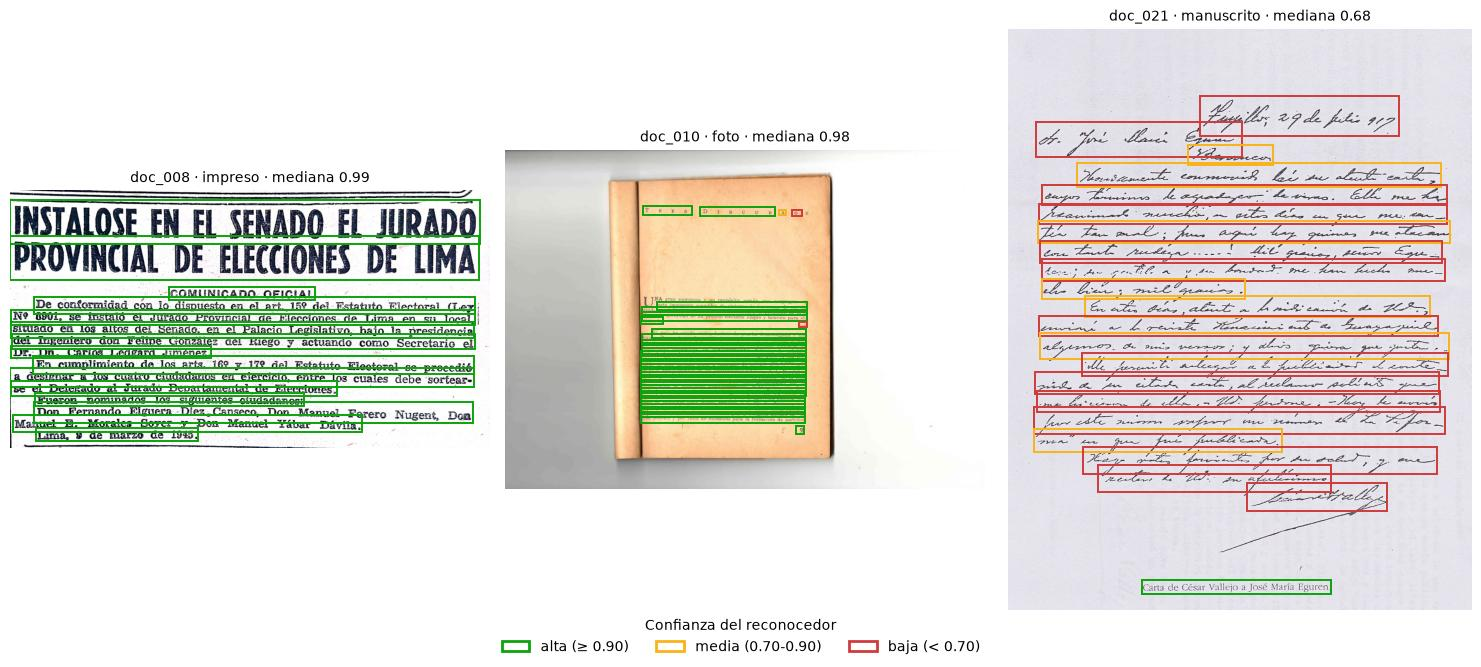

In [8]:
BIEN, DUDA, MAL = "#0ca30c", "#fab219", "#d03b3b"
LEYENDA = [Patch(facecolor="none", edgecolor=c, linewidth=2, label=t)
           for c, t in [(BIEN, "alta (≥ 0.90)"), (DUDA, "media (0.70-0.90)"), (MAL, "baja (< 0.70)")]]


def dibujar(doc_id, eje):
    eje.imshow(Image.open(DOCS / f"{doc_id}.jpg").convert("RGB"))
    for f in lecturas[doc_id].itertuples():
        color = BIEN if f.confianza >= 0.90 else DUDA if f.confianza >= 0.70 else MAL
        eje.add_patch(Rectangle((f.x0, f.y0), f.x1 - f.x0, f.y1 - f.y0, fill=False, linewidth=1.4, edgecolor=color))
    fila = catalogo.set_index("id").loc[doc_id]
    eje.set_title(f"{doc_id} · {fila.tipo} · mediana {fila.confianza_mediana:.2f}", fontsize=10)
    eje.axis("off")


fig, ejes = plt.subplots(1, 3, figsize=(15, 6.5))
for eje, doc_id in zip(ejes, ["doc_008", "doc_010", "doc_021"]):
    dibujar(doc_id, eje)
fig.legend(handles=LEYENDA, title="Confianza del reconocedor", loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

In [9]:
for doc_id in ["doc_008", "doc_010", "doc_021"]:
    print(f"── {doc_id}:", " · ".join(lecturas[doc_id]["texto"].head(8)), "\n")

── doc_008: INSTALOSE EN EL SENADO EL JURADO · PROVINCIAL DE ELECCIONES DE LIMA · COMUNICADO OFICIAL · De conformidad con lo dispuesto en el art. 15º del Estatuto Electoral (Ley · No 8901, se instaló el Jurado Provincial de Elecciones de Lima en su local, · situado en los altos del Senado, en el Palacio Legislativo, bajo la presidencia · del Ingeniero don Felipe González del Riego y actuando como Secretario el · Dr. Dn. Carlos Ledgard Jiménez. 

── doc_010: TRES · DISCUR · s · O · esta imponente asamblea de civismo: la esperanza de ver - · prada en el Perú la normalidad democrática, y el propósito de pro- · elamar la necesidad de un proceso electoral limpio y honesto para al. · canzarla. 

── doc_021: Frigillo;, 9 de pilis 917 · o. gori lavi Eque · Bannnco. · hosvemente coumovid bé su aleut carth, · eugos timins le ageadgeo de visao. Elle me ks · reanimad nenchio, n sets deas n gu me sar · tir tan anal; fes agri kay guimes sme alacan · coe trt rudaga...! lil graios, seers Egue. 



Tres documentos, tres comportamientos:

- **Impreso (doc_008, *La Crónica*, 1945).** Todas las cajas son verdes y el comunicado sale completo y
  ordenado, con los números de artículo y la ley citada («art. 15º», «Ley Nº 8901»). Entre lo poco que se
  le escapa está la «Nº» de la segunda línea, que leyó como «No».
- **Foto (doc_010, folleto de 1945 fotografiado abierto).** A pesar de la sombra del lomo y la curvatura,
  la mediana de confianza es 0,98: el detector encuentra el bloque de texto dentro de la foto. El punto
  débil es lo tipográfico raro, como el título en letras espaciadas («T r e s  D i s c u r s o s»), que
  se parte en «TRES · DISCUR · s · O».
- **Manuscrito (doc_021, carta de César Vallejo, 1917).** Casi todo sale en rojo o amarillo: «Frigillo;,
  9 de pilis 917» por *Trujillo, 29 de julio 917*. Igual que con el Acta de la Independencia en la clase,
  el modelo **falla avisando**: su confianza mediana cae a 0,68.

La tabla por tipo resume el patrón del corpus: en impresos y fotos la confianza mediana es 1,00 y menos
del 2 % de las líneas quedan bajo 0,90; en manuscritos la mediana baja a 0,83 y casi siete de cada diez
líneas son dudosas. En esta CPU cada página tomó alrededor de dos minutos.

### 2.2 ¿Hay documentos ilegibles?

El criterio de descarte es humano: un documento es **ilegible** si una persona tampoco puede leerlo. Los 25
se revisaron a ojo al armar el catálogo y todos se pueden leer. Como alarma automática marcamos los
documentos en los que el OCR devolvió menos de 3 líneas o una confianza mediana menor a 0,80: esos van
a revisión, pero no se descartan si el papel es legible.

In [10]:
alerta = catalogo[(catalogo["n_lineas"] < 3) | (catalogo["confianza_mediana"] < 0.80)]
print(f"Documentos en alerta: {len(alerta)} · descartados por ilegibles: 0")
alerta[["id", "tipo", "descripcion", "n_lineas", "confianza_mediana", "pct_lineas_dudosas"]].round(2)

Documentos en alerta: 4 · descartados por ilegibles: 0


,id,tipo,descripcion,n_lineas,confianza_mediana,pct_lineas_dudosas
16,doc_017,manuscrito,"Carta de Carlos J. Bachmann a Ricardo Palma (1912), p. 1",57,0.56,77.19
19,doc_020,manuscrito,"Carta de Carlos J. Bachmann a Ricardo Palma (1912), p. 4",30,0.64,100.00
20,doc_021,manuscrito,"Carta de César Vallejo a José María Eguren (Trujillo, 1917)",22,0.68,95.45
21,doc_022,manuscrito,"Tarjeta de Ricardo Palma (1912), recorte de la parte manuscrita",7,0.75,100.00


---
# B · Audio

## 3. El corpus: noticieros peruanos de la década de 1940

`fuentes_audio.py` reutiliza la idea de `datos.py` de la sesión 13. Consulta la API de Commons para
obtener la licencia y el autor de cada archivo, baja la versión liviana (240p; el audio Opus es el mismo
del original) con un User-Agent descriptivo y pausas de 1 a 2 s, y extrae el audio a WAV mono de 16 kHz.
De la película *Alerta en la frontera* (54 min) se usa solo un tramo de 5 min.

In [11]:
atribucion = fuentes_audio.bajar_noticieros()          # no vuelve a bajar lo que ya está en disco
atribucion["fecha_original"] = atribucion["fecha_original"].str.replace(r"date QS.*$", "", regex=True).str.strip()
atribucion["productora"] = (atribucion["autor"].str.extract(r"(Productora Huascarán|Nacional Films|National Films|Perú Sono Film|Peru Sono Film|Ministerio de Gobierno|Herrmann)", expand=False)
                            .replace({"National Films": "Nacional Films", "Peru Sono Film": "Perú Sono Film", "Herrmann": "Nacional Films (película)"})
                            .fillna("productora no identificada"))
atribucion["titulo"] = atribucion["titulo_commons"].str.removeprefix("File:").str.removesuffix(".webm")

print(f"{len(atribucion)} clips · {atribucion['duracion_seg'].sum() / 60:.1f} min · licencias: {atribucion['licencia'].value_counts().to_dict()}")
atribucion[["id", "titulo", "productora", "fecha_original", "licencia", "duracion_seg", "tramo_usado"]]

32 clips · 92.1 min · licencias: {'PDM-owner': 26, 'CC0': 4, 'Public domain': 1, 'CC BY 4.0': 1}


,id,titulo,productora,fecha_original,licencia,duracion_seg,tramo_usado
0,clip_001,Centenario del nacimiento de Don José Antonio Miro Quesada,Productora Huascarán,circa 1945,PDM-owner,42.7,completo
1,clip_002,Chosica celebra su cincuentenario,Nacional Films,1944,PDM-owner,140.6,completo
2,clip_003,Del Viejo Lima (Los Descalzos),Productora Huascarán,1940s,PDM-owner,97.7,completo
3,clip_004,Desfile militar por fiestas patrias,Ministerio de Gobierno,1945,PDM-owner,363.1,completo
4,clip_005,"El balcón de la libertad, una película documental",Ministerio de Gobierno,1940s,PDM-owner,278.4,completo
5,clip_006,El Dr. Eduardo Santos en el Country Club,productora no identificada,1940s,PDM-owner,72.0,completo
6,clip_007,El regreso del cardenal Guevara,Productora Huascarán,1940s,PDM-owner,32.5,completo
7,clip_008,El Satipo,Ministerio de Gobierno,1940s,PDM-owner,309.5,completo
8,clip_009,En el museo de Antropología y Arqueología,Productora Huascarán,1940s,CC0,311.8,completo
9,clip_010,En las ruinas de Chan Chan,Productora Huascarán,1940s,PDM-owner,80.6,completo


In [12]:
# Duplicados por hash entre los videos descargados
hash_audio = {p.stem: sha256(p.read_bytes()) for p in sorted((AUDIO / "originales").glob("clip_*.webm"))}
print(f"Videos: {len(hash_audio)} · hashes distintos: {len(set(hash_audio.values()))}")

Videos: 32 · hashes distintos: 32


## 4. ASR: VAD + faster-whisper + diarización

`procesar_audio.py` aplica a cada clip el flujo de `voz.py` de la sesión 13:

1. `cargar_audio`: cualquier formato → arreglo mono de 16 kHz;
2. `Transcriptor("faster-whisper").segmentos(audio, idioma="es")`: **VAD Silero activado** (no se le
   manda silencio ni música sola al modelo) y transcripción con Whisper large-v3-turbo en int8;
3. `diarizar`: una huella de voz por segmento y clustering jerárquico con umbral 0,7;
4. exportación de cada clip a **CSV** (segmentos), **SRT** (subtítulos) y **TXT** (lectura por turnos) en
   `datos/raw/audio/salidas/`.

Los resultados se guardan en caché: la transcripción completa tardó alrededor de una hora en esta CPU.

In [13]:
transcriptor = None
resultados = {}
for clip_id in atribucion["id"]:
    if not (pa.SALIDAS / f"{clip_id}.json").exists() and transcriptor is None:
        transcriptor = voz.Transcriptor(pa.MODELO_ASR)
    resultados[clip_id] = pa.procesar_clip(clip_id, transcriptor)

resumen_asr = pd.DataFrame([{k: v for k, v in r.items() if k != "segmentos"} for r in resultados.values()])
resumen_asr["factor_tiempo_real"] = (resumen_asr["segundos_procesamiento"] / resumen_asr["duracion_seg"]).round(2)
print(f"Audio: {resumen_asr['duracion_seg'].sum() / 60:.1f} min · voz detectada por el VAD: "
      f"{resumen_asr['segundos_voz'].sum() / 60:.1f} min · cómputo: {resumen_asr['segundos_procesamiento'].sum() / 60:.0f} min "
      f"(factor de tiempo real {resumen_asr['segundos_procesamiento'].sum() / resumen_asr['duracion_seg'].sum():.2f})")
resumen_asr.head(8)

Audio: 92.1 min · voz detectada por el VAD: 63.6 min · cómputo: 66 min (factor de tiempo real 0.71)


,id,duracion_seg,segundos_voz,n_segmentos,n_hablantes,segundos_procesamiento,factor_tiempo_real
0,clip_001,42.7,38.2,10,1,40.7,0.95
1,clip_002,140.6,126.9,13,1,89.3,0.64
2,clip_003,97.7,96.5,28,1,91.5,0.94
3,clip_004,363.1,330.4,43,2,379.7,1.05
4,clip_005,278.4,225.3,18,1,149.8,0.54
5,clip_006,72.0,58.3,9,1,53.9,0.75
6,clip_007,32.5,23.7,8,1,30.0,0.92
7,clip_008,309.5,197.9,57,2,311.4,1.01


### 4.1 Alucinaciones: el «¡Gracias!» de Whisper

Aun con el VAD, en los cierres musicales de algunos noticieros Whisper escribió **«¡Gracias!»**. Es la
misma alucinación que vimos en la sesión 13: el modelo aprendió de subtítulos de YouTube y la escribe
cuando oye música o aplausos. La revisión manual de las transcripciones encontró además, en el cierre
musical de la Semana Santa en Ayacucho (clip_025), una frase del narrador **repetida** sobre 30 segundos
de música: el VAD confirma que en ese tramo no hay voz.

Regla de limpieza, definida antes de calcular métricas: se elimina un segmento si su texto normalizado
está en la lista de alucinaciones conocidas de Whisper, o si repite literalmente un segmento anterior
del mismo clip.

In [14]:
ALUCINACIONES = {"gracias", "muchas gracias", "gracias por ver el video", "suscríbete",
                 "subtítulos realizados por la comunidad de amara org"}

eliminados = []
for clip_id, r in resultados.items():
    limpios, vistos = [], set()
    for s in r["segmentos"]:
        normal = voz.normalizar(s["texto"])
        if normal in ALUCINACIONES:
            eliminados.append({"id": clip_id, "inicio": s["inicio"], "texto": s["texto"], "motivo": "alucinación conocida de Whisper"})
        elif normal in vistos:
            eliminados.append({"id": clip_id, "inicio": s["inicio"], "texto": s["texto"], "motivo": "repite literalmente un segmento anterior"})
        else:
            limpios.append(dict(s))
        vistos.add(normal)
    r["segmentos_limpios"] = limpios

eliminados = pd.DataFrame(eliminados)
print(f"Segmentos eliminados: {len(eliminados)} en {eliminados['id'].nunique()} clips")
eliminados

Segmentos eliminados: 6 en 5 clips


,id,inicio,texto,motivo
0,clip_008,292.72,¡Gracias!,alucinación conocida de Whisper
1,clip_008,293.72,¡Gracias!,alucinación conocida de Whisper
2,clip_020,69.88,¡Gracias!,alucinación conocida de Whisper
3,clip_025,201.50,"Y así termina una de las más hermosas y tradicionales fiestas,",repite literalmente un segmento anterior
4,clip_027,232.01,¡Gracias!,alucinación conocida de Whisper
5,clip_031,352.98,¡Gracias!,alucinación conocida de Whisper


### 4.2 Diarización del clip con varios hablantes

Con los segmentos de faster-whisper, la diarización no separó voces en ningún noticiero, ni siquiera en
la **toma de mando de Bustamante y Rivero (clip_027, 1945)**, donde se oye al narrador y, en dos
momentos, a los oradores del Congreso. La causa: faster-whisper arma segmentos largos (frases completas)
que pueden mezclar dos voces, y la huella de voz de una mezcla no se parece a ninguna de las dos.

`voz.py` anticipa este problema: *«tramos cortos (pausas de 0,3 s, máximo 12 s) ayudan a separar
hablantes: cada tramo debería tener una sola voz»*. Para este clip hacemos una segunda pasada: primero
el VAD corta en tramos cortos, se transcribe cada tramo por separado y después se diariza.

In [15]:
diarizado_027 = pa.diarizar_por_tramos("clip_027")
tabla_027 = pd.DataFrame(diarizado_027["segmentos"])
voz_por_hablante = (tabla_027.assign(segundos=tabla_027["fin"] - tabla_027["inicio"])
                    .groupby("hablante").agg(tramos=("texto", "count"), segundos=("segundos", "sum")).round(1))
print(f"clip_027: {len(tabla_027)} tramos · hablantes detectados: {tabla_027['hablante'].nunique()}")
voz_por_hablante

clip_027: 59 tramos · hablantes detectados: 3


,tramos,segundos
hablante,,
H1,4,3.2
H2,26,121.1
H3,29,89.0


In [16]:
print(voz.a_texto([voz.Segmento(**s) for s in diarizado_027["segmentos"]])[:2500])

[00:00:00] H1: ¡Suscríbete!

[00:00:01] H2: cumpliendo los mandamientos de nuestra Constitución Democrática. El presidente Prado ingresa al interior del Congreso siendo recibido con aplausos. Estrecha calurosamente la mano del doctor Bustamante en signo de saludo y buen augurio para el futuro gobierno del Perú. El presidente Prado sube al estrado parlamentario y es saludado por el presidente del Congreso, doctor José Gálvez. El presidente Prado lee su mensaje. manifestando los votos que formula porque el nuevo gobierno que es la franca expresión popular en rumbe al país hacia una era de prosperidad y de grandeza. El presidente de la República, doctor Manuel Prado, Resigna el mando haciendo entrega de la banda presidencial al presidente del Congreso, doctor José Gálvez. quien se reviste después con los atributos del poder.

[00:00:57] H1: Gracias.

[00:01:00] H3: Buena fortuna. que ojalá siga presidiendo la marcha del país. en armonía con los anhelos de libertad. renovación y moralidad.

La segunda pasada separa tres grupos de voz:

- **H2, 121 s**: el narrador del noticiero;
- **H3, 89 s**: un orador grabado en directo en el Congreso. Por lo que dice («ha querido que sea yo,
  precisamente, quien reciba y transmita el signo sagrado del Poder Supremo»; «anunciar a vos, ciudadano
  presidente…») es, según el contexto, el presidente del Congreso que recibe la banda de Prado y la
  impone a Bustamante y Rivero. Sus dos intervenciones, separadas por un minuto de narración, quedan
  en el mismo grupo;
- **H1, 3 s**: cuatro tramos sobre aplausos y música donde Whisper escribió «¡Suscríbete!» y «Gracias».
  No son una persona: son alucinaciones, y la regla de 4.1 las elimina.

Después de la limpieza el clip queda con **2 hablantes**, renumerados por orden de aparición
(HABLANTE_1, el narrador; HABLANTE_2, el orador).

### 4.3 Falsos hablantes: cuando la «voz» es música

En clip_004 (desfile militar, 1945) la diarización encontró un segundo hablante, pero su único segmento,
«Sin olvidar…», dura 16 s según Whisper y el VAD solo encuentra **0,7 s de voz** dentro: es el narrador
cortado al final del rollo, sobre la marcha militar. La huella de voz de ese segmento es, sobre todo,
la de la música.

`voz.diarizar` ya evita que los segmentos de menos de 1 s voten al agrupar. Aplicamos la misma idea
con la voz real: un «hablante» cuya voz, medida con el VAD, suma menos de 2 s no se cuenta como
hablante, y sus segmentos pasan al hablante principal del clip.

In [17]:
def voz_real(audio, inicio, fin):
    """Segundos con voz, según el VAD, dentro de un segmento."""
    x = audio[int(inicio * voz.SR):int(fin * voz.SR)]
    return sum(b - a for a, b in voz.tramos_de_voz(x)) if len(x) > voz.SR // 2 else 0.0


fusionados = []
for clip_id, r in resultados.items():
    hablantes = {s["hablante"] for s in r["segmentos_limpios"]}
    if clip_id == "clip_027" or len(hablantes) < 2:
        continue
    audio = voz.cargar_audio(AUDIO / "wav" / f"{clip_id}.wav")
    principal = max(hablantes, key=lambda h: sum(s["fin"] - s["inicio"] for s in r["segmentos_limpios"] if s["hablante"] == h))
    for h in sorted(hablantes - {principal}):
        segmentos_h = [s for s in r["segmentos_limpios"] if s["hablante"] == h]
        segundos = sum(voz_real(audio, s["inicio"], s["fin"]) for s in segmentos_h)
        if segundos < 2:
            for s in segmentos_h:
                s["hablante"] = principal
            fusionados.append({"id": clip_id, "hablante": h, "segmentos": len(segmentos_h), "segundos_segun_whisper":
                               round(sum(s["fin"] - s["inicio"] for s in segmentos_h), 1), "voz_real_vad": round(segundos, 1),
                               "texto": " ".join(s["texto"] for s in segmentos_h)})
pd.DataFrame(fusionados)

,id,hablante,segmentos,segundos_segun_whisper,voz_real_vad,texto
0,clip_004,H2,1,16.1,0.9,Sin olvidar...


In [18]:
# El clip_027 usa la segunda pasada; los demás, los segmentos de faster-whisper ya limpios
for clip_id, r in resultados.items():
    if clip_id == "clip_027":
        quedan = [dict(s) for s in diarizado_027["segmentos"] if voz.normalizar(s["texto"]) not in ALUCINACIONES]
        # tras quitar las alucinaciones, los hablantes se renumeran por orden de aparición
        orden = {h: f"H{i}" for i, h in enumerate(dict.fromkeys(s["hablante"] for s in quedan), start=1)}
        for s in quedan:
            s["hablante"] = orden[s["hablante"]]
        r["segmentos_limpios"] = quedan
        quitados = [s["texto"] for s in diarizado_027["segmentos"] if voz.normalizar(s["texto"]) in ALUCINACIONES]
        print(f"clip_027, segunda pasada: {len(quitados)} alucinaciones eliminadas {quitados} · hablantes que quedan: {sorted(set(orden.values()))}")
    segmentos = [voz.Segmento(**s) for s in r["segmentos_limpios"]]
    base = pa.SALIDAS / f"{clip_id}_limpio"
    voz.a_tabla(segmentos).to_csv(base.with_suffix(".csv"), index=False)
    base.with_suffix(".srt").write_text(voz.a_srt(segmentos), encoding="utf-8")
    base.with_suffix(".txt").write_text(voz.a_texto(segmentos), encoding="utf-8")

print("Exportados por clip (CSV, SRT y TXT):", len(list(pa.SALIDAS.glob("*_limpio.srt"))))
print((pa.SALIDAS / "clip_027_limpio.srt").read_text(encoding="utf-8")[:600])

clip_027, segunda pasada: 4 alucinaciones eliminadas ['¡Suscríbete!', 'Gracias.', '¡Gracias!', '¡Gracias!'] · hablantes que quedan: ['H1', 'H2']
Exportados por clip (CSV, SRT y TXT): 32
1
00:00:01,530 --> 00:00:07,660
[H1] cumpliendo los mandamientos de nuestra Constitución Democrática.

2
00:00:11,220 --> 00:00:16,100
[H1] El presidente Prado ingresa al interior del Congreso siendo recibido con aplausos.

3
00:00:16,120 --> 00:00:22,820
[H1] Estrecha calurosamente la mano del doctor Bustamante en signo de saludo y buen augurio para el futuro gobierno del Perú.

4
00:00:24,660 --> 00:00:31,270
[H1] El presidente Prado sube al estrado parlamentario y es saludado por el presidente del Congreso, doctor José Gálvez.

5
00:00:32,540 --> 00:00:35,050
[H1] El presidente Prado lee su


### 4.4 ¿Hay audios sin voz?

Regla: un clip se descarta si el VAD encuentra menos de 5 segundos de voz o si, después de la limpieza,
no queda ningún segmento con texto.

In [19]:
def texto_con_hablantes(segmentos):
    """Une los segmentos en turnos con marcas [HABLANTE_n], como pide el enunciado."""
    turnos = []
    for s in segmentos:
        marca = "HABLANTE_" + s["hablante"].lstrip("H")
        if turnos and turnos[-1][0] == marca:
            turnos[-1][1].append(s["texto"])
        else:
            turnos.append((marca, [s["texto"]]))
    return " ".join(f"[{m}] " + " ".join(t) for m, t in turnos)


clips = atribucion[["id", "titulo", "productora", "fecha_original", "licencia", "fuente_url", "duracion_seg"]].copy()
clips["segundos_voz"] = [resultados[i]["segundos_voz"] for i in clips["id"]]
clips["n_segmentos"] = [len(resultados[i]["segmentos_limpios"]) for i in clips["id"]]
clips["n_hablantes"] = [len({s["hablante"] for s in resultados[i]["segmentos_limpios"]}) for i in clips["id"]]
clips["texto_asr_crudo"] = [texto_con_hablantes(resultados[i]["segmentos_limpios"]) for i in clips["id"]]
sin_voz = clips[(clips["segundos_voz"] < 5) | (clips["n_segmentos"] == 0)]
print(f"Clips sin voz descartados: {len(sin_voz)} · clips con 2 o más hablantes: {(clips['n_hablantes'] >= 2).sum()} "
      f"({', '.join(clips.loc[clips['n_hablantes'] >= 2, 'id'])})")

Clips sin voz descartados: 0 · clips con 2 o más hablantes: 1 (clip_027)


---
## 5. Seudonimización

Criterio de publicación acordado para este proyecto: se **conservan** las figuras públicas mencionadas en su
rol público (presidentes, ministros, candidatos, autoridades, escritores e intelectuales conocidos) y se
**reemplazan por un seudónimo** los particulares (personas que aparecen a título privado). Ningún texto
contiene DNI, direcciones personales ni teléfonos.

1. Un modelo NER en español (`mrm8488/bert-spanish-cased-finetuned-ner`) propone las personas mencionadas.
2. **Revisión humana**: el estudiante clasificó cada nombre propuesto. La tabla con los nombres reales queda en
   `datos/privado/revision_nombres.csv`, fuera de Git; aquí solo se muestran los conteos.
3. `voz.seudonimizar` reemplaza los particulares, también cuando el OCR o el ASR los escribieron con errores
   (comparación difusa con `rapidfuzz`).

In [20]:
textos = {**dict(zip(catalogo["id"], catalogo["texto_ocr_crudo"])), **dict(zip(clips["id"], clips["texto_asr_crudo"]))}
candidatos = seudonimos.candidatos(textos)
print(f"Personas propuestas por el NER: {len(candidatos)} nombres distintos en {candidatos['apariciones'].sum()} menciones")

Personas propuestas por el NER: 98 nombres distintos en 117 menciones


In [21]:
revision = pd.read_csv(DATOS / "privado" / "revision_nombres.csv")
print(revision["decision"].value_counts().to_string())
reemplazos = seudonimos.tabla_de_reemplazos(revision)
print(f"\nParticulares distintos: {len(set(reemplazos.values()))} · variantes de nombre buscadas: {len(reemplazos)}")

decision
figura_publica    79
descartar         26
particular         1

Particulares distintos: 1 · variantes de nombre buscadas: 1


In [22]:
conteo = {}
catalogo["texto_ocr"], catalogo["reemplazos"] = zip(*[seudonimos.aplicar(t, reemplazos) for t in catalogo["texto_ocr_crudo"]])
clips["texto_asr"], clips["reemplazos"] = zip(*[seudonimos.aplicar(t, reemplazos) for t in clips["texto_asr_crudo"]])
print(f"Entidades reemplazadas: {catalogo['reemplazos'].sum()} en documentos y {clips['reemplazos'].sum()} en audios "
      f"(total {catalogo['reemplazos'].sum() + clips['reemplazos'].sum()})")
pd.concat([catalogo.loc[catalogo["reemplazos"] > 0, ["id", "reemplazos"]], clips.loc[clips["reemplazos"] > 0, ["id", "reemplazos"]]])

Entidades reemplazadas: 1 en documentos y 0 en audios (total 1)


,id,reemplazos
14,doc_015,1


---
## 6. Análisis exploratorio

Tres preguntas con un gráfico cada una. El título de cada gráfico es la respuesta.

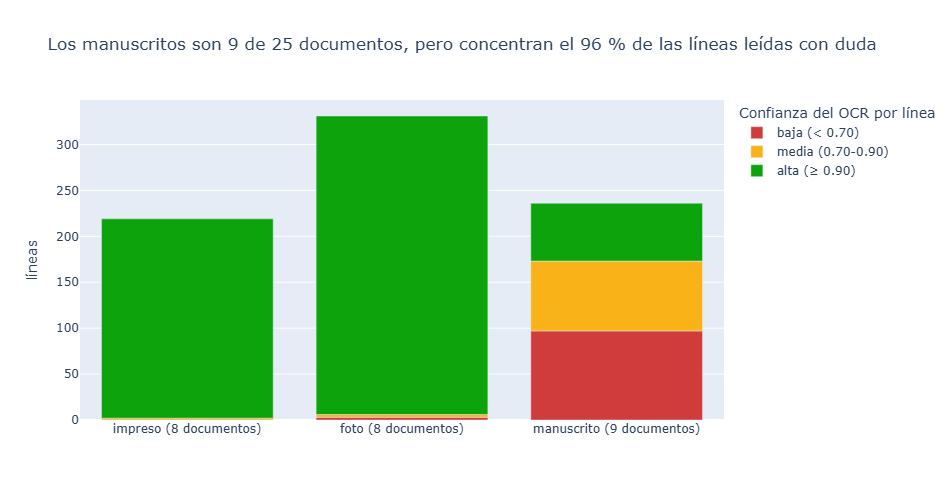

In [23]:
# 6.1 ¿Cómo se reparte el corpus por tipo y dónde se concentran las lecturas dudosas?
lineas = pd.concat([lecturas[i].assign(id=i) for i in catalogo["id"]], ignore_index=True)
lineas["tipo"] = lineas["id"].map(catalogo.set_index("id")["tipo"])
lineas["confianza del OCR"] = pd.cut(lineas["confianza"], [-1, 0.70, 0.90, 1.01],
                                     labels=["baja (< 0.70)", "media (0.70-0.90)", "alta (≥ 0.90)"])
docs_por_tipo = catalogo["tipo"].value_counts()
conteo = lineas.groupby(["tipo", "confianza del OCR"], observed=False).size().reset_index(name="líneas")
conteo["tipo"] = conteo["tipo"].map(lambda t: f"{t} ({docs_por_tipo[t]} documentos)")
pct_manuscritos = 100 * (lineas.loc[lineas["confianza"] < 0.90, "tipo"] == "manuscrito").mean()

fig = px.bar(conteo, x="tipo", y="líneas", color="confianza del OCR",
             color_discrete_map={"baja (< 0.70)": "#d03b3b", "media (0.70-0.90)": "#fab219", "alta (≥ 0.90)": "#0ca30c"},
             category_orders={"tipo": [f"{t} ({docs_por_tipo[t]} documentos)" for t in ["impreso", "foto", "manuscrito"]]},
             title=f"Los manuscritos son {docs_por_tipo['manuscrito']} de {len(catalogo)} documentos, "
                   f"pero concentran el {pct_manuscritos:.0f} % de las líneas leídas con duda",
             labels={"tipo": ""})
fig.update_layout(legend_title_text="Confianza del OCR por línea")
fig.show()

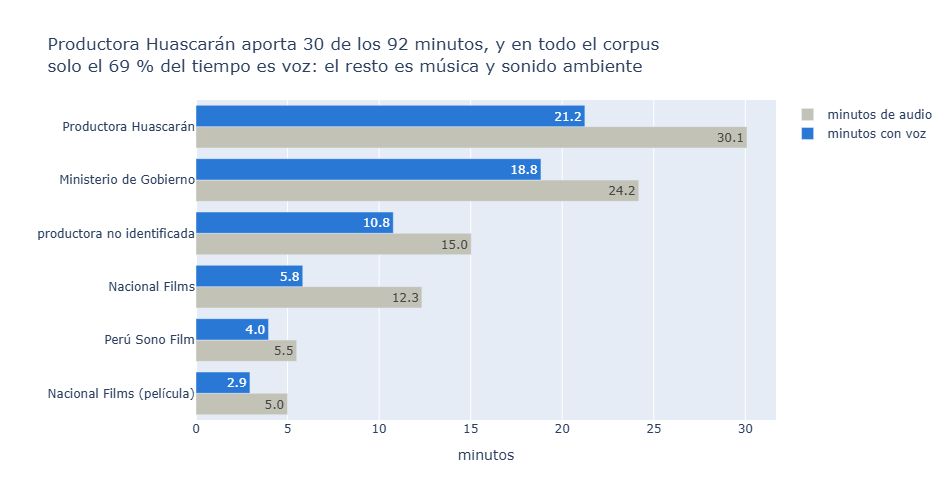

In [24]:
# 6.2 ¿Cuántos minutos aporta cada fuente y cuánto de eso es voz?
por_fuente = (clips.assign(**{"minutos de audio": clips["duracion_seg"] / 60, "minutos con voz": clips["segundos_voz"] / 60})
              .groupby("productora", as_index=False)[["minutos de audio", "minutos con voz"]].sum()
              .sort_values("minutos de audio"))
largo = por_fuente.melt(id_vars="productora", var_name="medida", value_name="minutos")
lider = por_fuente.iloc[-1]
pct_voz = 100 * clips["segundos_voz"].sum() / clips["duracion_seg"].sum()

fig = px.bar(largo, y="productora", x="minutos", color="medida", barmode="group", orientation="h", text_auto=".1f",
             color_discrete_map={"minutos de audio": "#c3c2b7", "minutos con voz": "#2a78d6"},
             title=f"{lider['productora']} aporta {lider['minutos de audio']:.0f} de los {clips['duracion_seg'].sum() / 60:.0f} minutos, "
                   f"y en todo el corpus<br>solo el {pct_voz:.0f} % del tiempo es voz: el resto es música y sonido ambiente",
             labels={"productora": ""})
fig.update_layout(legend_title_text=None)
fig.show()

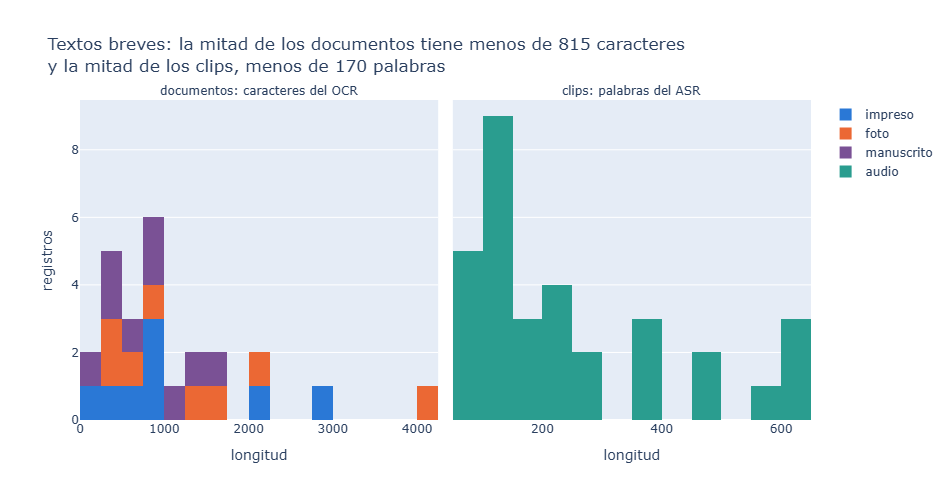

In [25]:
# 6.3 ¿Qué tan largos son los textos extraídos?
longitudes = pd.concat([
    pd.DataFrame({"medida": "documentos: caracteres del OCR", "valor": catalogo["texto_ocr"].str.len(), "tipo": catalogo["tipo"]}),
    pd.DataFrame({"medida": "clips: palabras del ASR", "valor": clips["texto_asr"].map(lambda t: len(re.sub(r"\[HABLANTE_\d+\]", " ", t).split())), "tipo": "audio"}),
], ignore_index=True)
med_c = longitudes.loc[longitudes["medida"].str.startswith("documentos"), "valor"].median()
med_p = longitudes.loc[longitudes["medida"].str.startswith("clips"), "valor"].median()

fig = px.histogram(longitudes, x="valor", color="tipo", facet_col="medida",
                   color_discrete_map={**COLORES, "audio": "#2a9d8f"},
                   title=f"Textos breves: la mitad de los documentos tiene menos de {med_c:.0f} caracteres<br>"
                         f"y la mitad de los clips, menos de {med_p:.0f} palabras",
                   labels={"valor": "longitud", "tipo": ""})
# intervalos propios en cada panel: 250 caracteres para el OCR y 50 palabras para el ASR
fig.for_each_trace(lambda t: t.update(bingroup=None, xbins=dict(start=0, size=50 if t.name == "audio" else 250)))
fig.update_xaxes(matches=None, title_text="longitud")
fig.update_yaxes(title_text="registros", col=1)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

**Lo que dicen los tres gráficos:**

1. **La dificultad del OCR no se reparte por igual.** Impresos y fotos aportan la mayoría de las líneas y
   casi todas con confianza alta, incluso las fotos con sombra y curvatura. Los manuscritos, con un tercio
   de los documentos, concentran casi todas las líneas dudosas. Para la prensa de 1939-1945 la foto con
   celular no es el problema: lo es la letra a mano.
2. **Un noticiero no es una entrevista.** Casi un tercio del tiempo de audio es música, marchas militares
   o sonido ambiente sin narración. Eso explica por qué el VAD es indispensable (evita que Whisper
   «transcriba» la música) y por qué las alucinaciones aparecieron justo en los cierres musicales.
3. **Los textos son cortos y desiguales.** Los avisos y comunicados son breves; la cola larga a la
   derecha de los documentos son las columnas completas de periódico y la primera página de la ley.
   En audio, la cantidad de palabras sigue a la duración de la voz, no a la del clip.

## 7. Validación: los extremos tienen que ser coherentes con los histogramas

In [26]:
cols = ["id", "tipo", "descripcion", "n_lineas", "n_caracteres", "confianza_mediana"]
print("Los 3 documentos con el OCR más largo:")
display(catalogo.nlargest(3, "n_caracteres")[cols].round(2))
print("Los 3 documentos con el OCR más corto:")
display(catalogo.nsmallest(3, "n_caracteres")[cols].round(2))

Los 3 documentos con el OCR más largo:


,id,tipo,descripcion,n_lineas,n_caracteres,confianza_mediana
14,doc_015,foto,"La Crónica (1945): informes de los ministros y avisos, columna curvada",134,4246,0.99
3,doc_004,impreso,"Ley 8901, Estatuto Electoral (1939), primera página",80,2959,0.99
15,doc_016,foto,"El Comercio (1939): «La manifestación de ayer en la Plaza de Acho», columna inclinada",83,2162,1.00


Los 3 documentos con el OCR más corto:


,id,tipo,descripcion,n_lineas,n_caracteres,confianza_mediana
0,doc_001,impreso,El Comercio (1939): aviso de manifestación cívica en la Plaza de Acho,9,204,1.00
21,doc_022,manuscrito,"Tarjeta de Ricardo Palma (1912), recorte de la parte manuscrita",7,237,0.75
11,doc_012,foto,«Tres discursos» (1945): portadilla del discurso del Partido Vanguardia Socialista,9,266,1.00


In [27]:
clips["n_palabras"] = clips["texto_asr"].map(lambda t: len(re.sub(r"\[HABLANTE_\d+\]", " ", t).split()))
cols = ["id", "titulo", "duracion_seg", "segundos_voz", "n_palabras", "n_hablantes"]
print("Los 3 clips más largos:")
display(clips.nlargest(3, "duracion_seg")[cols])
print("Los 3 clips más cortos:")
display(clips.nsmallest(3, "duracion_seg")[cols])

Los 3 clips más largos:


,id,titulo,duracion_seg,segundos_voz,n_palabras,n_hablantes
12,clip_013,"Inti Raymi, fiesta milenaria",493.7,150.2,366,1
3,clip_004,Desfile militar por fiestas patrias,363.1,330.4,617,1
30,clip_031,Visiones de la provincia de Huancayo,353.5,249.6,624,1


Los 3 clips más cortos:


,id,titulo,duracion_seg,segundos_voz,n_palabras,n_hablantes
6,clip_007,El regreso del cardenal Guevara,32.5,23.7,62,1
0,clip_001,Centenario del nacimiento de Don José Antonio Miro Quesada,42.7,38.2,102,1
20,clip_021,Reunión de boy-scouts en Lima,46.5,32.5,52,1


Los extremos coinciden con los histogramas y tienen explicación:

- **Más largos:** la columna de *La Crónica* con los informes de los ministros (doc_015, unos 4200
  caracteres) es la barra aislada a la derecha del histograma; le siguen la primera página de la Ley 8901
  y la crónica de la manifestación de 1939 en la Plaza de Acho. Son textos largos de verdad, no
  repeticiones del OCR.
- **Más cortos:** un aviso de cuatro líneas (doc_001), el recorte manuscrito de la tarjeta de Palma
  (doc_022) y la portadilla de un discurso (doc_012). El aviso doc_001 es corto, además, porque el OCR
  **omitió su primera línea** («Se invita a la ciudadanía a concurrir a la…»): el detector no la vio y,
  como en el menú de la clase, lo que no se detecta no deja rastro de baja confianza.
- **Clips:** el más largo, el Inti Raymi (clip_013, 494 s), tiene solo 150 s de voz, porque la mayor parte
  es danza y música. Por eso tiene menos palabras que clips más cortos, como el de Huancayo. Los más
  cortos (32 a 47 s) son noticias breves de una sola toma, con entre 50 y 100 palabras.

## 8. Exportación

In [28]:
licencia_corta = {"CC0": "CC0", "Public Domain Mark": "Public Domain Mark", "Dominio público": "dominio público",
                  "CC BY-SA 3.0": "CC BY-SA 3.0"}
documentos = pd.DataFrame({
    "id": catalogo["id"],
    "archivo": catalogo["archivo"],
    "tipo": catalogo["tipo"],
    "fuente": [f"{f} ({licencia_corta.get(l, 'dominio público en el Perú' if 'D. Leg. 822, art. 53' in l else 'texto oficial no protegido' if 'art. 9' in l else 'uso académico, imagen no publicable')})"
               for f, l in zip(catalogo["fuente"], catalogo["licencia"])],
    "texto_ocr": catalogo["texto_ocr"],
    "modelo_ocr": pd_ocr.CONFIG_OCR,
    "texto_referencia": "",
    "descripcion": catalogo["descripcion"],
    "imagen_publicable": catalogo["imagen_publicable"],
    "n_lineas": catalogo["n_lineas"],
    "n_caracteres": catalogo["texto_ocr"].str.len(),
    "confianza_mediana": catalogo["confianza_mediana"].round(3),
})

transcripciones = pd.DataFrame({
    "id": clips["id"],
    "archivo_audio": [f"datos/raw/audio/wav/{i}.wav" for i in clips["id"]],
    "duracion_seg": clips["duracion_seg"],
    "idioma": "es (configurado; español peruano: noticieros de productoras limeñas, según la BNP)",
    "texto_asr": clips["texto_asr"],
    "modelo_asr": [pa.CONFIG_ASR + (" + segunda pasada por tramos VAD para diarizar" if i == "clip_027" else "") for i in clips["id"]],
    "n_hablantes": clips["n_hablantes"],
    "texto_referencia": "",
    "titulo": clips["titulo"],
    "productora": clips["productora"],
    "fecha_original": clips["fecha_original"],
    "segundos_voz": clips["segundos_voz"],
    "n_palabras": clips["n_palabras"],
})

fuentes = pd.concat([
    pd.DataFrame({
        "id": catalogo["id"], "modalidad": "documento", "fuente_url": catalogo["fuente_url"], "licencia": catalogo["licencia"],
        "acceso": [("Descarga desde Wikimedia Commons (fuentes_documentos.bajar_commons)" if o.startswith("File:")
                    else f"PDF de capturas propias del estudiante, «{Path(o).name}», página {p}; no se publica el PDF completo")
                   for o, p in zip(catalogo["origen"], catalogo["pagina"])],
    }),
    pd.DataFrame({
        "id": clips["id"], "modalidad": "audio", "fuente_url": clips["fuente_url"], "licencia": clips["licencia"],
        "acceso": "python fuentes_audio.py: baja la versión 240p desde Commons y extrae el audio a WAV mono de 16 kHz"
                  + pd.Series(["" if i != "clip_032" else " (tramo de 600 a 900 s)" for i in clips["id"]]),
    }),
], ignore_index=True)

documentos.to_csv(DATOS / "documentos.csv", index=False)
transcripciones.to_csv(DATOS / "transcripciones.csv", index=False)
fuentes.to_csv(DATOS / "fuentes.csv", index=False)
for nombre, tabla in [("documentos", documentos), ("transcripciones", transcripciones), ("fuentes", fuentes)]:
    print(f"datos/{nombre}.csv: {tabla.shape}")

datos/documentos.csv: (25, 12)
datos/transcripciones.csv: (32, 13)
datos/fuentes.csv: (57, 5)


In [29]:
documentos.head(5)

,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia,descripcion,imagen_publicable,n_lineas,n_caracteres,confianza_mediana
0,doc_001,datos/raw/documentos/doc_001.jpg,impreso,"El Comercio, Lima, 1939 (captura propia) (dominio público en el Perú)",gran manifestación cívica que se\ntributará a\nManuel\nPrado\nCandidato Nacional a la ...,PaddleOCR 3.7.0 · PP-OCRv6 medium (det + rec multilingüe) · motor Paddle en CPU (sin o...,,El Comercio (1939): aviso de manifestación cívica en la Plaza de Acho,True,9,204,0.999
1,doc_002,datos/raw/documentos/doc_002.jpg,impreso,"El Comercio, Lima, 1939 (captura propia) (dominio público en el Perú)",Mensaje del Presidente de la\nRepública\nDe la Oficina de Informaciones del\nPerú se n...,PaddleOCR 3.7.0 · PP-OCRv6 medium (det + rec multilingüe) · motor Paddle en CPU (sin o...,,El Comercio (1939): «Mensaje del Presidente de la República»,True,13,421,0.996
2,doc_003,datos/raw/documentos/doc_003.jpg,impreso,"El Comercio, Lima, 1939 (captura propia) (dominio público en el Perú)","VIVERES PARA EL\n""AUXILIO SOCIAL""\nE ESPAÑA\nDE\nAnte el inminente derrumbe de la zona...",PaddleOCR 3.7.0 · PP-OCRv6 medium (det + rec multilingüe) · motor Paddle en CPU (sin o...,,El Comercio (1939): «Víveres para el Auxilio Social de España»,True,12,745,0.991
3,doc_004,datos/raw/documentos/doc_004.jpg,impreso,"Ley N.° 8901, 1939 (captura propia) (texto oficial no protegido)",LEY N° 8901\ngales en el orden electoral y puede dificul-\nPRIMERA PARTE DE LA LEGISLA...,PaddleOCR 3.7.0 · PP-OCRv6 medium (det + rec multilingüe) · motor Paddle en CPU (sin o...,,"Ley 8901, Estatuto Electoral (1939), primera página",True,80,2959,0.994
4,doc_005,datos/raw/documentos/doc_005.jpg,impreso,"El Comercio, Lima, 1945 (captura propia) (dominio público en el Perú)",PARTIDO NaCIONAL LABORISTA\nJuan\nJorge Salas\nCANDIDATO DEL PARTIDO A UNA DIPUTACION ...,PaddleOCR 3.7.0 · PP-OCRv6 medium (det + rec multilingüe) · motor Paddle en CPU (sin o...,,El Comercio (1945): aviso del Partido Nacional Laborista,True,41,2023,0.992


In [30]:
transcripciones.head(5)

,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia,titulo,productora,fecha_original,segundos_voz,n_palabras
0,clip_001,datos/raw/audio/wav/clip_001.wav,42.7,"es (configurado; español peruano: noticieros de productoras limeñas, según la BNP)",[HABLANTE_1] El centenario del nacimiento del ilustre periodista don José Antonio Miro...,"faster-whisper large-v3-turbo (int8, CPU, beam 5, VAD Silero on, idioma=es)",1,,Centenario del nacimiento de Don José Antonio Miro Quesada,Productora Huascarán,circa 1945,38.2,102
1,clip_002,datos/raw/audio/wav/clip_002.wav,140.6,"es (configurado; español peruano: noticieros de productoras limeñas, según la BNP)","[HABLANTE_1] ... kilómetros de la Plaza de Armas de Lima, en un paisaje que bordan flo...","faster-whisper large-v3-turbo (int8, CPU, beam 5, VAD Silero on, idioma=es)",1,,Chosica celebra su cincuentenario,Nacional Films,1944,126.9,184
2,clip_003,datos/raw/audio/wav/clip_003.wav,97.7,"es (configurado; español peruano: noticieros de productoras limeñas, según la BNP)",[HABLANTE_1] Rincones románticos de la Lima Vieja Evocación maravillosa del pasado Acá...,"faster-whisper large-v3-turbo (int8, CPU, beam 5, VAD Silero on, idioma=es)",1,,Del Viejo Lima (Los Descalzos),Productora Huascarán,1940s,96.5,220
3,clip_004,datos/raw/audio/wav/clip_004.wav,363.1,"es (configurado; español peruano: noticieros de productoras limeñas, según la BNP)",[HABLANTE_1] año realizado en el campo de Marte adquirió proporciones inusitadas de en...,"faster-whisper large-v3-turbo (int8, CPU, beam 5, VAD Silero on, idioma=es)",1,,Desfile militar por fiestas patrias,Ministerio de Gobierno,1945,330.4,617
4,clip_005,datos/raw/audio/wav/clip_005.wav,278.4,"es (configurado; español peruano: noticieros de productoras limeñas, según la BNP)","[HABLANTE_1] el ejército libertador, se conserva la casa desde cuyo balcón proclamara ...","faster-whisper large-v3-turbo (int8, CPU, beam 5, VAD Silero on, idioma=es)",1,,"El balcón de la libertad, una película documental",Ministerio de Gobierno,1940s,225.3,278


In [31]:
fuentes.sample(5, random_state=1)

,id,modalidad,fuente_url,licencia,acceso
47,clip_023,audio,https://commons.wikimedia.org/wiki/File:Scouts_peruanos.webm,PDM-owner,python fuentes_audio.py: baja la versión 240p desde Commons y extrae el audio a WAV mo...
2,doc_003,documento,local: Elecciones 1939/Fuentes Primarias/El Comercio - 1939 - Convocatoria a Plebiscit...,"Captura propia; dominio público en el Perú (D. Leg. 822, art. 53: obra de persona jurí...","PDF de capturas propias del estudiante, «El Comercio - 1939 - Convocatoria a Plebiscit..."
34,clip_010,audio,https://commons.wikimedia.org/wiki/File:En_las_ruinas_de_Chan_Chan.webm,PDM-owner,python fuentes_audio.py: baja la versión 240p desde Commons y extrae el audio a WAV mo...
45,clip_021,audio,https://commons.wikimedia.org/wiki/File:Reuni%C3%B3n_de_boy-scouts_en_Lima.webm,PDM-owner,python fuentes_audio.py: baja la versión 240p desde Commons y extrae el audio a WAV mo...
38,clip_014,audio,https://commons.wikimedia.org/wiki/File:Mar_Y_Playa_En_Miraflores.webm,PDM-owner,python fuentes_audio.py: baja la versión 240p desde Commons y extrae el audio a WAV mo...


## Qué hicimos

| Paso | Herramienta | Resultado |
|---|---|---|
| Corpus de documentos | PDF propios + Commons, `pymupdf` | 25 imágenes (8 impresos, 8 fotos, 9 manuscritos), 4 candidatos descartados con motivo |
| Duplicados | SHA-256 + *average hash* | 0 copias exactas entre los elegidos; un diploma duplicado descartado |
| OCR | PaddleOCR 3.7 (PP-OCRv6) | texto, confianza y caja por línea; respaldo crudo en `datos/raw/documentos/ocr/` |
| Corpus de audio | API de Commons, `fuentes_audio.py` | 32 clips, 92 min, todos con licencia libre |
| ASR | `voz.py`: VAD + faster-whisper turbo | segmentos con tiempos; CSV, SRT y TXT por clip |
| Limpieza de audio | lista de alucinaciones + repeticiones | segmentos «¡Gracias!» eliminados; 0 clips sin voz |
| Diarización | WeSpeaker + clustering; segunda pasada por tramos VAD | clip multihablante con marcas `[HABLANTE_n]` |
| Seudonimización | NER + revisión humana + `voz.seudonimizar` | particulares reemplazados; figuras públicas conservadas |
| EDA y validación | Plotly Express | 3 gráficos con títulos analíticos; extremos revisados |
| Exportación | pandas | `documentos.csv`, `transcripciones.csv`, `fuentes.csv` |